In [1]:
%load_ext autoreload 
%autoreload 2 

# Area of Law

Example of strongest neighbors observed in filtered subsets.

## 0. Set Up

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt

from network_pluralism.access.utils.labels import get_well_written_sections
from network_pluralism.access.utils.df import get_data_for_perspectives
from network_pluralism.setup.params import COURT_1_COLOR, COURT_2_COLOR, COURT_3_COLOR
from network_pluralism.visualization.bar_plots import (
    show_perspectives_as_bars,
)


In [3]:
def set_rcParams(**kwargs):
    params = {
        "pdf.fonttype": 42,
        "text.usetex": True,
        "font.family": "serif",
        #"text.latex.preamble": r"\usepackage{amssymb}\usepackage{amsmath}\usepackage{amsfonts}\usepackage{lmodern}",
        "font.size": 12,
        "legend.fontsize": 14,
        "legend.title_fontsize": 16,
        "axes.labelsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "axes.spines.right": False,
        "axes.spines.top": False,
        "legend.columnspacing": 1.0,
        "legend.frameon": False,
        "lines.linewidth": 3,
    }
    for param in kwargs:
        if param in plt.rcParams.keys():
            params[param] = kwargs[param]
    for k, v in params.items():
        plt.rcParams[k] = v


set_rcParams()

In [4]:
EXPORT_PATH = Path("../../figures_and_results/areas_of_law")
EXPORT_PATH.mkdir(parents=True, exist_ok=True)

## 1. Computation

In [5]:
investigated_unit = "bgb_187"
judicial_granularity = 2
legislative_granularity = 1

In [6]:
section_export_path  = EXPORT_PATH / investigated_unit
section_export_path.mkdir(exist_ok=True)

In [7]:
penal_panels = [
    "BGH_1. Strafsenat",
    "BGH_4. Strafsenat",
    "BGH_3. Strafsenat",
    "BGH_2. Strafsenat",
    "BGH_5. Strafsenat",
    "BGH_6. Strafsenat",
    "BGH_Großer Senat für Strafsachen",
]
civil_panels = [
    "BGH_12. Zivilsenat",
    "BGH_9. Zivilsenat",
    "BGH_8. Zivilsenat",
    "BGH_5. Zivilsenat",
    "BGH_4. Zivilsenat",
    "BGH_7. Zivilsenat",
    "BGH_6. Zivilsenat",
    "BGH_11. Zivilsenat",
    "BGH_1. Zivilsenat",
    "BGH_6a. Zivilsenat",
    "BGH_3. Zivilsenat",
    "BGH_2. Zivilsenat",
    "BGH_10. Zivilsenat",
    "BGH_Kartellsenat",
    "BGH_13. Zivilsenat",
    "BGH_10a. Zivilsenat",
    "BGH_Großer Senat für Zivilsachen",
]

In [8]:
perspectives = [
    {
        "statute": investigated_unit,
        "d": judicial_granularity,
        "s": legislative_granularity,
        "from_institutions": civil_panels,
    },
    {
        "statute": investigated_unit,
        "d": judicial_granularity,
        "s": legislative_granularity,
        "from_institutions": "BVerwG",
    },
    {
        "statute": investigated_unit,
        "d": judicial_granularity,
        "s": legislative_granularity,
        "from_institutions": penal_panels,
    },
    # {"statute": "bgb_187", "d": 3, "s": 1, "from_institutions": "BVerfG"},
]
perspectives_df = get_data_for_perspectives(perspectives=perspectives, only_union=True)

Out Matrix of shape (74214, 93645)
Out Matrix of shape (74214, 93645)
Out Matrix of shape (74214, 93645)
Out Matrix of shape (74214, 93645)
Out Matrix of shape (74214, 93645)
Out Matrix of shape (74214, 93645)
Out Matrix of shape (74214, 93645)
Out Matrix of shape (74214, 93645)
Out Matrix of shape (74214, 93645)


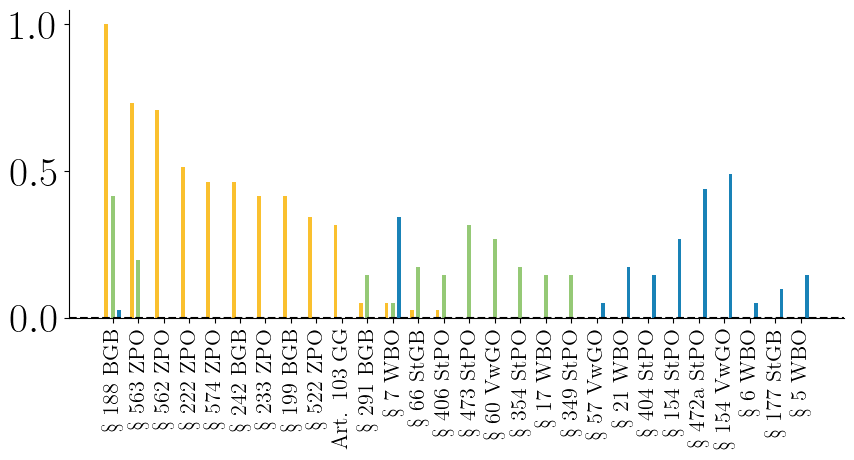

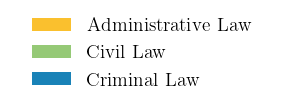

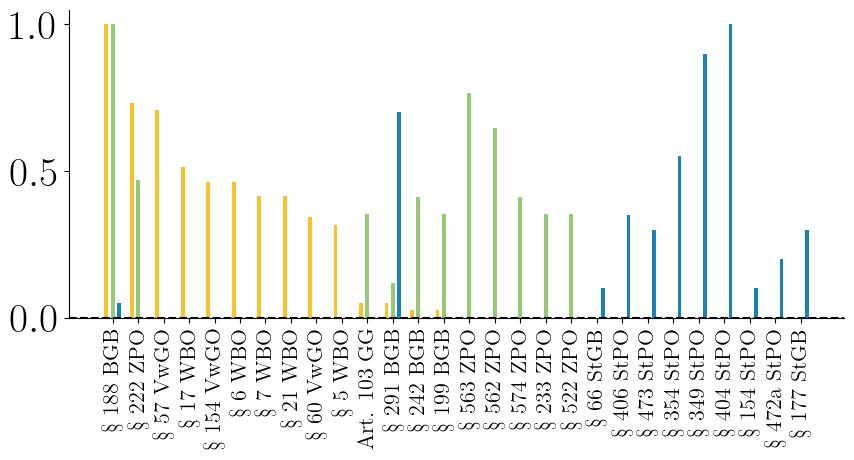

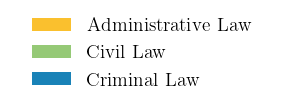

In [9]:
for normalize_scope in ["global", "local"]:
    x_labels = list(get_well_written_sections(list(perspectives_df.index)).values())
    perspectives_df.sort_values(
        [f"1_count_norm_local", f"0_count_norm_local"], ascending=False, inplace=True
    )
    show_perspectives_as_bars(
        [
            perspectives_df[f"1_count_norm_{normalize_scope}"].to_list(),
            perspectives_df[f"0_count_norm_{normalize_scope}"].to_list(),
            perspectives_df[f"2_count_norm_{normalize_scope}"].to_list(),
        ],
        x_labels=x_labels,
        perspective_labels=[
            "Administrative Law",
            "Civil Law",
            "Criminal Law",
        ],
        rotation=90,
        legend_in_extra_plot=True,
        colors=[COURT_1_COLOR, COURT_2_COLOR, COURT_3_COLOR],
        fig_size=(10, 4),
        width=0.15,
        legend=True,
        save_dir=section_export_path,
        file_name=f"coocs_per_perspective_{judicial_granularity}_{normalize_scope}.pdf",
    )